In [1]:
import torch

print("PyTorch:", torch.__version__)
print("Notebook is working!")

PyTorch: 2.14.1+cpu
Notebook is working!


# Foundations of Generative AI — Assignment 2

## Autoregressive Text Generation Using RNN, BiRNN, LSTM, and GRU

**Dataset:** Frankenstein by Mary Shelley  
**Source:** https://www.gutenberg.org/ebooks/84

### Objective
To train and compare four recurrent neural network models
for next-word prediction and autoregressive text generation.

In [2]:

import re
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

# Load dataset
DATA_PATH = Path("data/frankenstein.txt")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}"
    )

raw_text = DATA_PATH.read_text(encoding="utf-8")

# Remove Project Gutenberg header and footer
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"

start = raw_text.find(start_marker)
end = raw_text.find(end_marker)

if start == -1 or end == -1 or end <= start:
    raise ValueError("Could not find Gutenberg boundary markers.")

start = raw_text.find("\n", start)
clean_text = raw_text[start + 1:end]

# Normalize whitespace and lowercase the text
clean_text = clean_text.lower()
clean_text = re.sub(r"\s+", " ", clean_text).strip()

# Keep words, contractions, numbers, and punctuation
tokens = re.findall(
    r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]",
    clean_text
)

# Save cleaned text
Path("data/frankenstein_cleaned.txt").write_text(
    " ".join(tokens), encoding="utf-8"
)

print("Dataset loaded and cleaned successfully.")
print("Original characters:", len(raw_text))
print("Cleaned characters:", len(clean_text))
print("Total tokens:", len(tokens))
print("Unique tokens:", len(set(tokens)))
print("\nFirst 40 tokens:")
print(tokens[:40])


Dataset loaded and cleaned successfully.
Original characters: 438841
Cleaned characters: 418285
Total tokens: 86013
Unique tokens: 7021

First 40 tokens:
['frankenstein', ';', 'or', ',', 'the', 'modern', 'prometheus', 'by', 'mary', 'wollstonecraft', '(', 'godwin', ')', 'shelley', 'contents', 'letter', '1', 'letter', '2', 'letter', '3', 'letter', '4', 'chapter', '1', 'chapter', '2', 'chapter', '3', 'chapter', '4', 'chapter', '5', 'chapter', '6', 'chapter', '7', 'chapter', '8', 'chapter']


In [3]:

# Split chronologically: 80% training, 10% validation, 10% test
n = len(tokens)

train_end = int(n * 0.80)
val_end = int(n * 0.90)

train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

# Vocabulary is built from training data only
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

counter = Counter(train_tokens)
vocab_words = [PAD_TOKEN, UNK_TOKEN] + sorted(counter.keys())

word_to_id = {
    word: idx for idx, word in enumerate(vocab_words)
}
id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

PAD_ID = word_to_id[PAD_TOKEN]
UNK_ID = word_to_id[UNK_TOKEN]
VOCAB_SIZE = len(vocab_words)

# Convert text to integer IDs
train_ids = [word_to_id.get(w, UNK_ID) for w in train_tokens]
val_ids = [word_to_id.get(w, UNK_ID) for w in val_tokens]
test_ids = [word_to_id.get(w, UNK_ID) for w in test_tokens]

print("Training tokens:", len(train_ids))
print("Validation tokens:", len(val_ids))
print("Test tokens:", len(test_ids))
print("Vocabulary size:", VOCAB_SIZE)
print("Unknown validation tokens:", val_ids.count(UNK_ID))
print("Unknown test tokens:", test_ids.count(UNK_ID))


Training tokens: 68810
Validation tokens: 8601
Test tokens: 8602
Vocabulary size: 6414
Unknown validation tokens: 327
Unknown test tokens: 392


In [4]:

SEQ_LEN = 12
BATCH_SIZE = 64

class NextWordDataset(Dataset):
    def __init__(self, token_ids, seq_len=12):
        self.token_ids = torch.tensor(
            token_ids, dtype=torch.long
        )
        self.seq_len = seq_len

    def __len__(self):
        return max(0, len(self.token_ids) - self.seq_len)

    def __getitem__(self, index):
        x = self.token_ids[index:index + self.seq_len]
        y = self.token_ids[index + self.seq_len]
        return x, y

train_dataset = NextWordDataset(train_ids, SEQ_LEN)
val_dataset = NextWordDataset(val_ids, SEQ_LEN)
test_dataset = NextWordDataset(test_ids, SEQ_LEN)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))
print("Test sequences:", len(test_dataset))

# Inspect the first example
x, y = train_dataset[0]

print("\nInput words:")
print([id_to_word[int(i)] for i in x])

print("\nExpected next word:")
print(id_to_word[int(y)])

print("\nInput shape:", tuple(x.shape))


Training sequences: 68798
Validation sequences: 8589
Test sequences: 8590

Input words:
['frankenstein', ';', 'or', ',', 'the', 'modern', 'prometheus', 'by', 'mary', 'wollstonecraft', '(', 'godwin']

Expected next word:
)

Input shape: (12,)


In [5]:

class TextGenerator(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_dim=128,
        model_type="RNN"
    ):
        super().__init__()

        self.model_type = model_type.upper()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim
        )

        if self.model_type == "RNN":
            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        elif self.model_type == "BIRNN":
            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True,
                bidirectional=True
            )
            output_dim = hidden_dim * 2

        elif self.model_type == "LSTM":
            self.recurrent = nn.LSTM(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        elif self.model_type == "GRU":
            self.recurrent = nn.GRU(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        else:
            raise ValueError("Unsupported model type")

        self.fc = nn.Linear(output_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        output, _ = self.recurrent(embedded)

        # Predict the next word from the final time step
        last_output = output[:, -1, :]

        logits = self.fc(last_output)

        return logits


# Create all four models
model_types = ["RNN", "BIRNN", "LSTM", "GRU"]

models = {
    name: TextGenerator(
        vocab_size=VOCAB_SIZE,
        embedding_dim=64,
        hidden_dim=128,
        model_type=name
    ).to(DEVICE)
    for name in model_types
}

for name, model in models.items():
    parameters = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    print(f"{name}: {parameters:,} trainable parameters")


RNN: 1,262,734 trainable parameters
BIRNN: 2,108,558 trainable parameters
LSTM: 1,337,230 trainable parameters
GRU: 1,312,398 trainable parameters


In [6]:
sample_x, sample_y = next(iter(train_loader))

for name, model in models.items():
    logits = model(sample_x)
    print(
        name,
        "| input:", tuple(sample_x.shape),
        "| output:", tuple(logits.shape)
    )

RNN | input: (64, 12) | output: (64, 6414)
BIRNN | input: (64, 12) | output: (64, 6414)
LSTM | input: (64, 12) | output: (64, 6414)
GRU | input: (64, 12) | output: (64, 6414)


In [7]:

import math
import json
import os

# Create output folders
Path("results").mkdir(exist_ok=True)
Path("plots").mkdir(exist_ok=True)
Path("generated_text").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)

# Training settings
EPOCHS = 5
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()


def evaluate_model(model, data_loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_words = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(inputs)
            loss = criterion(logits, targets)

            batch_size = targets.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (
                logits.argmax(dim=1) == targets
            ).sum().item()

            total_words += batch_size

    average_loss = total_loss / total_words
    accuracy = total_correct / total_words

    # Clamp only for numerical safety
    perplexity = math.exp(min(average_loss, 50))

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "perplexity": perplexity
    }


def train_model(model, model_name):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = []
    best_val_loss = float("inf")
    best_path = Path("models") / f"{model_name.lower()}_best.pt"

    start_time = time.time()

    for epoch in range(EPOCHS):
        model.train()

        total_loss = 0.0
        total_examples = 0

        for inputs, targets in train_loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, targets)

            loss.backward()

            # Stabilize recurrent-network training
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

        train_loss = total_loss / total_examples
        val_metrics = evaluate_model(model, val_loader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_perplexity": val_metrics["perplexity"]
        })

        print(
            f"{model_name} | Epoch {epoch + 1}/{EPOCHS} "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_metrics['loss']:.4f} "
            f"| Val Accuracy: {val_metrics['accuracy']:.4f} "
            f"| Val Perplexity: {val_metrics['perplexity']:.2f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]

            torch.save(
                model.state_dict(), best_path
            )

    elapsed_time = time.time() - start_time

    # Restore the best validation checkpoint
    model.load_state_dict(
        torch.load(best_path, map_location=DEVICE)
    )

    print(
        f"\n{model_name} finished in "
        f"{elapsed_time / 60:.2f} minutes."
    )

    return history, elapsed_time


In [8]:

all_histories = {}
training_times = {}

for model_name in model_types:
    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    history, elapsed = train_model(
        models[model_name],
        model_name
    )

    all_histories[model_name] = history
    training_times[model_name] = elapsed

# Save training history
with open("results/training_history.json", "w") as f:
    json.dump(all_histories, f, indent=2)

print("\nAll four models have finished training.")



Training: RNN
RNN | Epoch 1/5 | Train Loss: 6.0539 | Val Loss: 5.6558 | Val Accuracy: 0.1259 | Val Perplexity: 285.96
RNN | Epoch 2/5 | Train Loss: 5.2790 | Val Loss: 5.5147 | Val Accuracy: 0.1432 | Val Perplexity: 248.32
RNN | Epoch 3/5 | Train Loss: 4.8991 | Val Loss: 5.4942 | Val Accuracy: 0.1509 | Val Perplexity: 243.27
RNN | Epoch 4/5 | Train Loss: 4.5854 | Val Loss: 5.5084 | Val Accuracy: 0.1532 | Val Perplexity: 246.76
RNN | Epoch 5/5 | Train Loss: 4.3109 | Val Loss: 5.5442 | Val Accuracy: 0.1572 | Val Perplexity: 255.75

RNN finished in 5.80 minutes.

Training: BIRNN
BIRNN | Epoch 1/5 | Train Loss: 5.9836 | Val Loss: 5.6114 | Val Accuracy: 0.1303 | Val Perplexity: 273.54
BIRNN | Epoch 2/5 | Train Loss: 5.1365 | Val Loss: 5.5189 | Val Accuracy: 0.1479 | Val Perplexity: 249.35
BIRNN | Epoch 3/5 | Train Loss: 4.6699 | Val Loss: 5.5411 | Val Accuracy: 0.1498 | Val Perplexity: 254.97
BIRNN | Epoch 4/5 | Train Loss: 4.2978 | Val Loss: 5.5965 | Val Accuracy: 0.1533 | Val Perplexity: 

In [9]:

test_results = []

for model_name, model in models.items():
    metrics = evaluate_model(model, test_loader)

    test_results.append({
        "Model": model_name,
        "Test Loss": metrics["loss"],
        "Test Perplexity": metrics["perplexity"],
        "Test Accuracy (%)": metrics["accuracy"] * 100,
        "Training Time (minutes)": (
            training_times[model_name] / 60
        )
    })

results_df = pd.DataFrame(test_results)

results_df = results_df.sort_values(
    "Test Perplexity"
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)


Model  Test Loss  Test Perplexity  Test Accuracy (%)  Training Time (minutes)
 LSTM     5.6176         275.2373            14.7846                   5.4703
  GRU     5.6298         278.6080            14.9709                   7.8190
  RNN     5.6866         294.8746            13.3760                   5.8039
BIRNN     5.7289         307.6274            13.7951                   9.7087


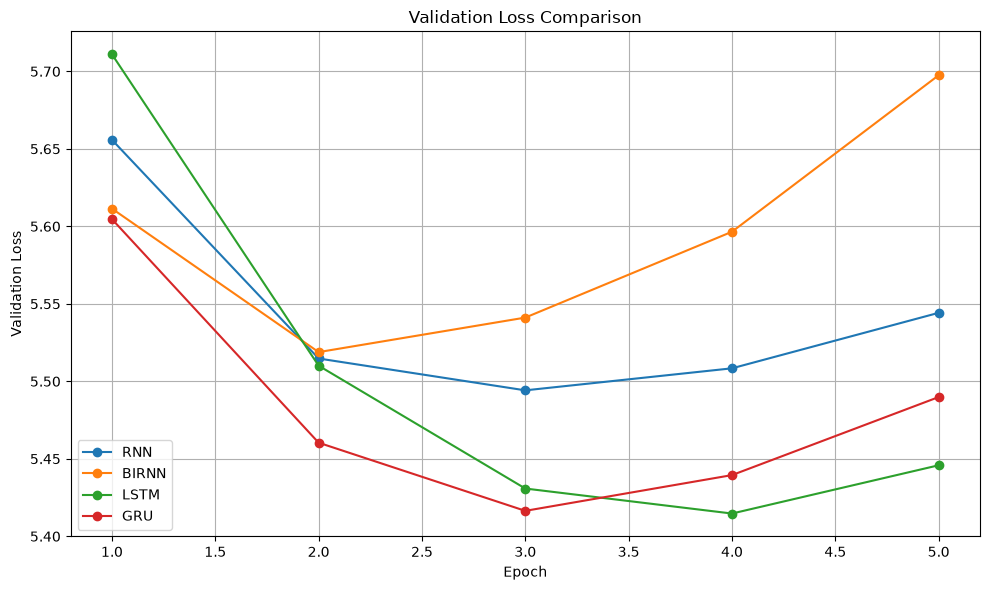

In [10]:

plt.figure(figsize=(10, 6))

for model_name, history in all_histories.items():
    epochs = [row["epoch"] for row in history]
    val_losses = [row["val_loss"] for row in history]

    plt.plot(
        epochs, val_losses,
        marker="o", label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/validation_loss.png", dpi=150)
plt.show()


In [11]:

import torch
import torch.nn.functional as F
import re
import json
from pathlib import Path

TEMPERATURES = [0.5, 1.0, 1.5]
GENERATE_WORDS = 40

# Use the same seed sequences for every model
SEED_SEQUENCES = [
    "it was on a dreary night of november",
    "i had worked hard for nearly two years"
]


def generate_text(model, seed, temperature, num_words=40):
    model.eval()

    seed_tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]",
        seed.lower()
    )

    # Convert seed words into vocabulary IDs
    context = [
        word_to_id.get(token, UNK_ID)
        for token in seed_tokens
    ]

    generated = seed_tokens.copy()

    with torch.no_grad():
        for _ in range(num_words):
            # Keep the most recent 12 tokens
            current_context = context[-12:]

            x = torch.tensor(
                [current_context],
                dtype=torch.long,
                device=DEVICE
            )

            logits = model(x)[0]

            # Temperature controls sampling randomness
            logits = logits / temperature

            # Avoid generating padding or unknown tokens
            logits[PAD_ID] = -float("inf")
            logits[UNK_ID] = -float("inf")

            probabilities = F.softmax(logits, dim=-1)

            next_id = torch.multinomial(
                probabilities, num_samples=1
            ).item()

            next_word = id_to_word[next_id]

            context.append(next_id)
            generated.append(next_word)

    # Remove spaces before punctuation
    text = " ".join(generated)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    text = re.sub(r"\(\s+", "(", text)
    text = re.sub(r"\s+\)", ")", text)

    return text


# Generate and save all samples
generation_results = {}

for model_name, model in models.items():
    generation_results[model_name] = {}

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    for seed in SEED_SEQUENCES:
        generation_results[model_name][seed] = {}

        for temperature in TEMPERATURES:
            sample = generate_text(
                model,
                seed,
                temperature,
                GENERATE_WORDS
            )

            generation_results[model_name][seed][
                str(temperature)
            ] = sample

            print(
                f"\nSeed: {seed}"
                f"\nTemperature: {temperature}"
                f"\nGenerated: {sample}\n"
            )

# Save the generated samples
with open(
    "generated_text/temperature_samples.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        generation_results,
        file,
        indent=2,
        ensure_ascii=False
    )

print("All generated samples saved successfully.")



MODEL: RNN

Seed: it was on a dreary night of november
Temperature: 0.5
Generated: it was on a dreary night of november. i was to become a few moments had been took. i was engaged, and my arrival, and my resolution, and the latter of a great d mon. the day of the power, which


Seed: it was on a dreary night of november
Temperature: 1.0
Generated: it was on a dreary night of november hysterics and and barrier related by one day to muscles and painful him as it. all the first time of the barrier afford are still depending in the scene of a lady belief. a small form, henry


Seed: it was on a dreary night of november
Temperature: 1.5
Generated: it was on a dreary night of november often stood my shocking?, my die awe before hate penetrate — this exile apprehension unhappy parched that the pronouncing feeble of approbation conjectured apprehended it beneath. in sunset villains with lips elevated those light. those attempted


Seed: i had worked hard for nearly two years
Temperature: 0.5


In [12]:

import pandas as pd
import re

generation_metrics = []

for model_name, seeds in generation_results.items():
    for seed, temperatures in seeds.items():
        for temperature, text in temperatures.items():

            tokens = re.findall(
                r"[a-z]+(?:'[a-z]+)?|[0-9]+",
                text.lower()
            )

            if not tokens:
                continue

            unique_ratio = len(set(tokens)) / len(tokens)

            repeated_rate = (
                1 - unique_ratio
            )

            generation_metrics.append({
                "Model": model_name,
                "Seed": seed,
                "Temperature": float(temperature),
                "Total Words": len(tokens),
                "Distinct Words": len(set(tokens)),
                "Unique Word Ratio": unique_ratio,
                "Repeated Word Rate": repeated_rate
            })

generation_df = pd.DataFrame(generation_metrics)

print(generation_df.round(3).to_string(index=False))

generation_df.to_csv(
    "results/generation_metrics.csv",
    index=False
)


Model                                   Seed  Temperature  Total Words  Distinct Words  Unique Word Ratio  Repeated Word Rate
  RNN   it was on a dreary night of november          0.5           41              29              0.707               0.293
  RNN   it was on a dreary night of november          1.0           45              35              0.778               0.222
  RNN   it was on a dreary night of november          1.5           43              39              0.907               0.093
  RNN i had worked hard for nearly two years          0.5           43              29              0.674               0.326
  RNN i had worked hard for nearly two years          1.0           42              38              0.905               0.095
  RNN i had worked hard for nearly two years          1.5           46              46              1.000               0.000
BIRNN   it was on a dreary night of november          0.5           43              27              0.628             